In [15]:
from scipy.optimize import brentq
import numpy as np
from datetime import datetime
import time, sys, os, pyvisa, subprocess
import matplotlib as mpl
import matplotlib.pyplot as plt
import time, math
import serial

In [16]:
hp34461a = 'GPIB0::22::INSTR'
vna_addr = 'GPIB0::16::INSTR'
port ='S21'

bkpower_addr = 'USB0::0x2EC7::0x9130::800885011797670040::INSTR'

In [3]:
rm = pyvisa.ResourceManager()

print(rm.list_resources())

('USB0::0x2EC7::0x9130::800885011797670040::INSTR', 'ASRL1::INSTR', 'ASRL3::INSTR', 'GPIB0::10::INSTR', 'GPIB0::12::INSTR', 'GPIB0::15::INSTR', 'GPIB0::16::INSTR', 'GPIB0::21::INSTR', 'GPIB0::22::INSTR', 'GPIB0::27::INSTR')


In [4]:
from Instruments.hp34461A import *
from Instruments.vna_config import *
from Instruments.power_supply import*
from Instruments.SRS_SG396_lo import *
from Routines.dep_evap import *
from Routines.res_to_temp import *
from Routines.retrieve_vna_data import *
from Routines.vna_analysis import *

In [6]:
f0_arr = []

T_arr = []

Q_arr = []

In [11]:
def wait_for_stable_resistance(timeout=180, check_interval=1,machineGPIB=hp34461a):
    """
    Wait until the resistance value remains unchanged for the specified timeout.
    
    :param timeout: The time in seconds for which the resistance value must remain unchanged.
    :param check_interval: The interval in seconds at which to check the resistance value.
    """
    start_time = time.time()
    initial_value = round(hp34461a_get_ohm_4pt(machineGPIB),2)
    
    while True:
        time.sleep(check_interval)
        current_value = round(hp34461a_get_ohm_4pt(machineGPIB),2)
        
        if np.abs(current_value - initial_value) > 0.005:
            start_time = time.time()
            initial_value = current_value
        
        elapsed_time = time.time() - start_time
        
        if elapsed_time >= timeout:
            print('success')
            break


In [5]:
resValue =  np.abs(hp34461a_get_ohm_4pt(hp34461a))

conv_value = R2T_900(resValue)

print(resValue)

print(conv_value)

1062.5456
16.501470901867258


c:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Routines\res_to_temp.py:22: RuntimeWarning: divide by zero encountered in log
  log_T = np.log(T)


In [ ]:
#wait_for_stable_resistance()

resValue =  np.abs(hp34461a_get_ohm_4pt(hp34461a))

conv_value = R2T_900(resValue)

freq_initial, s_data_initial, L_data_initial, times = SingleScan_VNA(vna_addr, f = 6.993, span = 25, del_time = 60, n_points = 201, BW = 50E3, power = -10, name = f'{round(conv_value, 2)} K_first_scan', forplot = False, to_save = False)

freqs, s_data, L_data, times = SingleScan_VNA(vna_addr, f = freq_initial[np.argmax(s_data_initial)], span = 10, del_time = 60, n_points = 201, BW = 50E3, power = -10, name = f'{conv_value} K', forplot = True, to_save = False)

6.993
25
Started at 2025-06-25 11_30_47.394936


KeyboardInterrupt: 

6.98936000784827
Q is: 5182.5448471567215


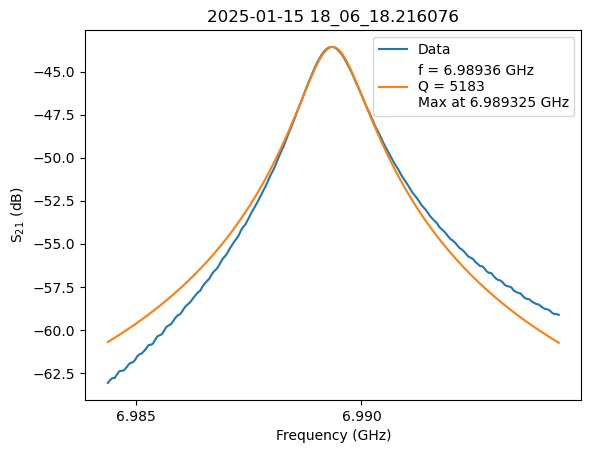

In [16]:
f0, Q = single_scan_analysis (freqs, s_data, L_data, times)

In [124]:
f0_arr.append(f0)
Q_arr.append(Q)
T_arr.append(conv_value)

In [125]:
print(f0_arr)
print(Q_arr)
print(T_arr)

[7.014525671230165, 7.014525797013622, 7.014528895989853, 7.014501267232172, 7.01448568678328, 7.0142864761145916, 7.013994779565007, 7.013607524494642, 7.013133873868581, 7.012576473118555, 7.013803628958762, 7.0143949060764745]
[5548.456887996383, 5551.031329259583, 5558.717905555248, 5580.45633982214, 5596.199643408375, 5572.882254244992, 5514.833162137421, 5425.716914611072, 5325.4235171007385, 5214.091822163418, 5469.538238626454, 5588.292808279796]
[5.3112793333813135, 5.311906698765577, 5.6335129070936185, 6.5691181338722915, 7.841151854375195, 9.230972977859535, 10.692216572118307, 12.228349420554197, 13.801443778480301, 15.407113508990033, 11.492735021931104, 8.55528884862824]


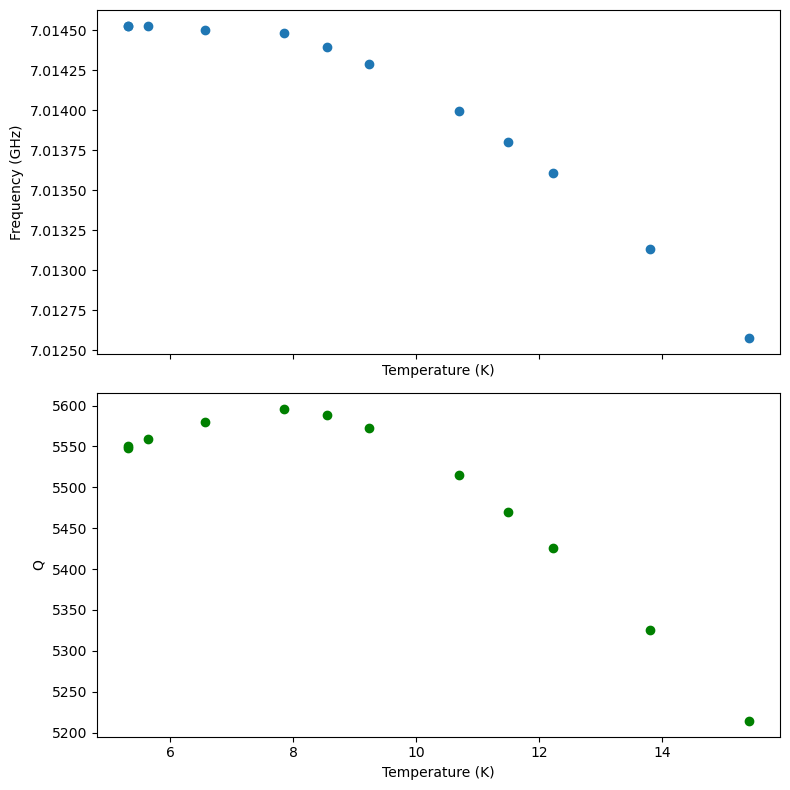

In [126]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize = (8, 8), sharex = True)
ax1.scatter(T_arr, f0_arr)
ax1.set_xlabel("Temperature (K)")
ax1.set_ylabel('Frequency (GHz)')


ax2.scatter(T_arr, Q_arr, color = 'g')
ax2.set_xlabel("Temperature (K)")
ax2.set_ylabel("Q")

plt.tight_layout()

plt.show()

In [8]:
marker_x_value, marker_y_value = marker_find_max(vna_gpib=vna_addr)


print(float(marker_x_value)/1.0E9)

7.0115


In [15]:
data_save = r"blah"

In [16]:
freq_initial, s_data_initial, L_data_initial, times = SingleScan_VNA(vna_addr, f = 2.22, span = 100, del_time = 60, n_points = 201, BW = 50E3, power = -10.00, name = f'K_first_scan', forplot = False, to_save = False, data_dir = data_save)

freqs, s_data, L_data, times = SingleScan_VNA(vna_addr, f = freq_initial[np.argmax(s_data_initial)], span = 40, del_time = 60, n_points = 201, BW = 50E3, power = -10.00, name = f'K_second_scan, 0dBm', forplot = True, to_save = False, data_dir = data_save)

f0, q = single_scan_analysis( f = freqs, S = s_data, L = L_data, time_stamp = 0, forplot = True)

VisaIOError: VI_ERROR_NLISTENERS (-1073807265): No listeners condition is detected (both NRFD and NDAC are deasserted).

+5.00000000000E+001
 0.1
[ 0.   0.1  0.2  0.3  0.4  0.5  0.6  0.7  0.8  0.9  1.   1.1  1.2  1.3
  1.4  1.5  1.6  1.7  1.8  1.9  2.   2.1  2.2  2.3  2.4  2.5  2.6  2.7
  2.8  2.9  3.   3.1  3.2  3.3  3.4  3.5  3.6  3.7  3.8  3.9  4.   4.1
  4.2  4.3  4.4  4.5  4.6  4.7  4.8  4.9  5.   5.1  5.2  5.3  5.4  5.5
  5.6  5.7  5.8  5.9  6.   6.1  6.2  6.3  6.4  6.5  6.6  6.7  6.8  6.9
  7.   7.1  7.2  7.3  7.4  7.5  7.6  7.7  7.8  7.9  8.   8.1  8.2  8.3
  8.4  8.5  8.6  8.7  8.8  8.9  9.   9.1  9.2  9.3  9.4  9.5  9.6  9.7
  9.8  9.9 10.  10.1 10.2 10.3 10.4 10.5 10.6 10.7 10.8 10.9 11.  11.1
 11.2 11.3 11.4 11.5 11.6 11.7 11.8 11.9 12.  12.1 12.2 12.3 12.4 12.5
 12.6 12.7 12.8 12.9 13.  13.1 13.2 13.3 13.4 13.5 13.6 13.7 13.8 13.9
 14.  14.1 14.2 14.3 14.4 14.5 14.6 14.7 14.8 14.9 15.  15.1 15.2 15.3
 15.4 15.5 15.6 15.7 15.8 15.9 16.  16.1 16.2 16.3 16.4 16.5 16.6 16.7
 16.8 16.9 17.  17.1 17.2 17.3 17.4 17.5 17.6 17.7 17.8 17.9 18.  18.1
 18.2 18.3 18.4 18.5 18.6 18.7 18.8 18.9 19.  19.1 1

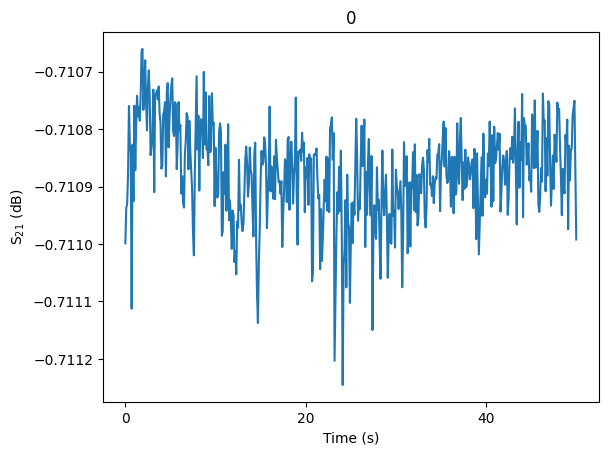

In [ ]:
time_swept, time_dwelled = prepare_for_cw_spec(vna_freq_GHz= 7.011582475048594, vna_power_dBm = -20, bw_hz = 10, num_points = 501, vna_gpib=vna_addr)


configure_display(vna_gpib=vna_addr, format = "PHAS")

times, S, L, phase, phase_rad = retrieve_cw_data(vna_gpib=vna_addr, del_time = math.ceil(float(time_swept)), num_avgs = 1, forplot = True,
                                                 to_save = False)




In [15]:
vna = rm.open_resource(vna_addr)

cw_freq = vna.query("SENS1:FREQ:CW?")

print(cw_freq)

vna.close()


+7.01158359822E+009



In [8]:
R2T_900_silent(np.abs(hp34461a_get_ohm_4pt(hp34461a)))

4.125346658871112

2.228
100
Started at 2026-01-06 11_30_26.354386


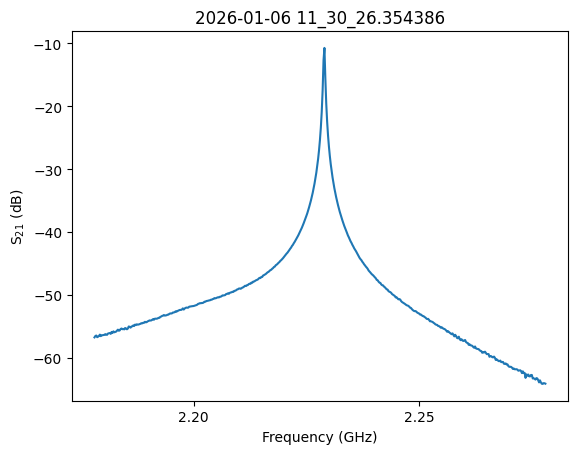

(array([2.178 , 2.1782, 2.1784, 2.1786, 2.1788, 2.179 , 2.1792, 2.1794,
        2.1796, 2.1798, 2.18  , 2.1802, 2.1804, 2.1806, 2.1808, 2.181 ,
        2.1812, 2.1814, 2.1816, 2.1818, 2.182 , 2.1822, 2.1824, 2.1826,
        2.1828, 2.183 , 2.1832, 2.1834, 2.1836, 2.1838, 2.184 , 2.1842,
        2.1844, 2.1846, 2.1848, 2.185 , 2.1852, 2.1854, 2.1856, 2.1858,
        2.186 , 2.1862, 2.1864, 2.1866, 2.1868, 2.187 , 2.1872, 2.1874,
        2.1876, 2.1878, 2.188 , 2.1882, 2.1884, 2.1886, 2.1888, 2.189 ,
        2.1892, 2.1894, 2.1896, 2.1898, 2.19  , 2.1902, 2.1904, 2.1906,
        2.1908, 2.191 , 2.1912, 2.1914, 2.1916, 2.1918, 2.192 , 2.1922,
        2.1924, 2.1926, 2.1928, 2.193 , 2.1932, 2.1934, 2.1936, 2.1938,
        2.194 , 2.1942, 2.1944, 2.1946, 2.1948, 2.195 , 2.1952, 2.1954,
        2.1956, 2.1958, 2.196 , 2.1962, 2.1964, 2.1966, 2.1968, 2.197 ,
        2.1972, 2.1974, 2.1976, 2.1978, 2.198 , 2.1982, 2.1984, 2.1986,
        2.1988, 2.199 , 2.1992, 2.1994, 2.1996, 2.1998, 2.2   , 

In [6]:
SingleScan_VNA(vna_addr, f = 2.228, span = 100, n_points = 501, BW = 1E3, power = -30, forplot = True, to_save = False)

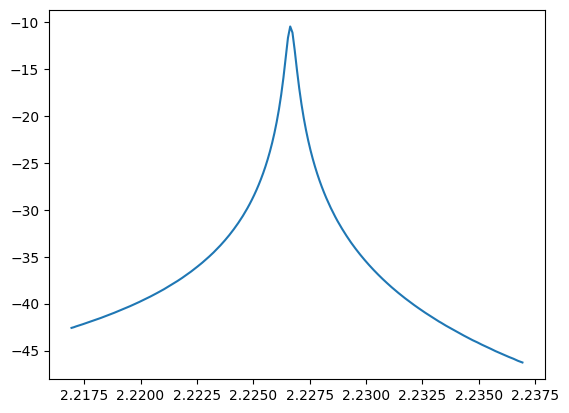

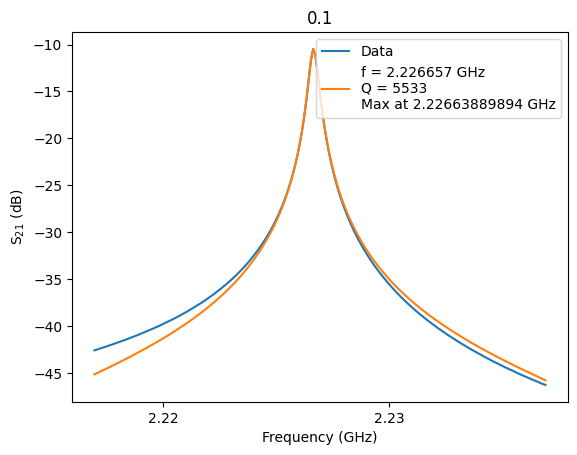

2.226656574135208
Q is: 5533.453038697517
2.226656574135208 5533.453038697517


In [6]:
df = pd.read_csv(r"C:\Users\crow104\Desktop\IceT_SD\RealTimeGrowthMonitor\IceT_SD\Calibrations\real_time_fq_10082025\2025-10-08 19_11_40.598848_outarray_24.95 K_second_scan, 0dBm.csv")

f_data = df.iloc[0, 1:].to_numpy()/1e9
S_data = df.iloc[1, 1:].to_numpy()
phase_data = df.iloc[2, 1:].to_numpy()
L_data = 10**((S_data - np.max(S_data))/10)

plt.plot(f_data, S_data)
plt.show()

fit_f, fit_q = single_scan_analysis(f_data, S_data, L_data, "0.1")
plt.show()

print(fit_f, fit_q)

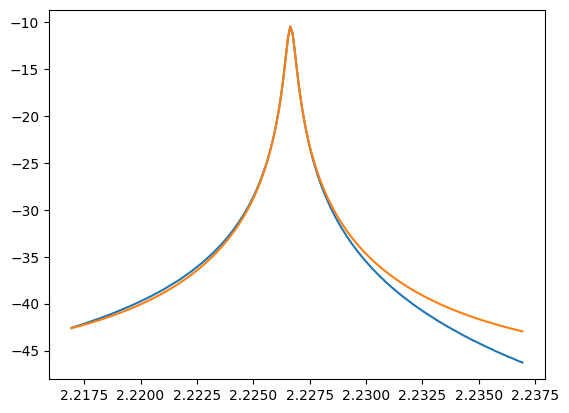

In [13]:
def internalQLorentzian1(x, Qi, Qc, c):
    return ((4*Qi*Qc)/(Qi+Qc)**2)*(1/(1 + 4*fit_q**2*((x-fit_f)/fit_f)**2)) + c

params, covs = curve_fit(internalQLorentzian1, f_data, L_data, p0 = [5000, 3000, 0.2*(np.max(f_data) - np.min(f_data))])


lin_return = internalQLorentzian1(f_data, *params)
s_return = S_fit = np.log10(lin_return) * 10 + np.max(S_data)
plt.plot(f_data, S_data)
plt.plot(f_data, s_return)

plt.show()



In [19]:
Qint = 1/(1/5533 - 1/9000)

In [40]:
Vmag = np.sqrt(50*(0.0031622777))
print(Vmag)

C = np.pi/(4*fit_f*1E9*2*np.pi*50)

print(C)

0.39763536688780593
1.1227595800088542e-12


In [41]:
energy_on_resonance = 0.5*(Vmag**2)*C

p_diss = (2*np.pi*fit_f*1E9)*((energy_on_resonance)/Qint)

print(p_diss)



8.645906869730403e-08


In [37]:
print((np.pi*((4.22/2)**2)*1.016) - 3*(np.pi*(0.335/2)**2*(0.99)) - (np.pi*(4.08/2)**2*0.0508))



13.284530079151946


In [38]:
(np.pi*(4.22/2)**2) - 3*(np.pi*(0.335/2)**2)

13.722260726385281

6.74666
50
Started at 2026-04-03 15_29_43.699835


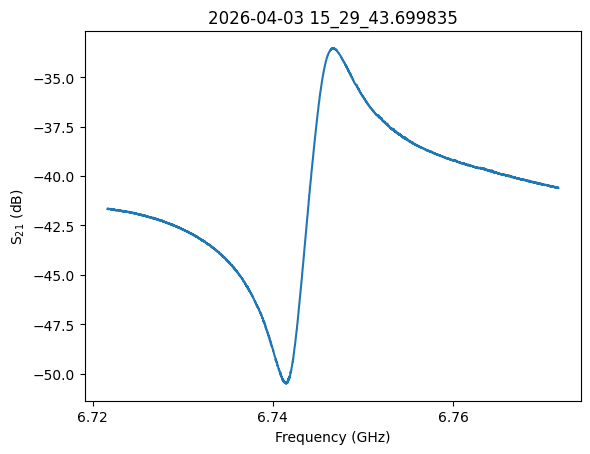

In [21]:
os.mkdir(r"C:\Users\crow104\Desktop\IceT_SD\RealTimeGrowthMonitor\IceT_SD\Data\before_after_wirebond")
filepath = r"C:\Users\crow104\Desktop\IceT_SD\RealTimeGrowthMonitor\IceT_SD\Data\before_after_wirebond"

#freq_initial, real_initial, imag_initial, times = SingleScan_VNA_realimag(vna_addr, f = 1.15387, span = 1, del_time = 20, n_points = 1001, BW = 1E3, power = 10.00, name = '', forplot = True, to_save = False, data_dir = filepath, meas = "S22")

#f_max = freq_initial[np.argmin(np.sqrt(real_initial**2 + imag_initial**2))]

f, r, i, t = SingleScan_VNA(vna_addr, f = 6.746660, span = 50, del_time = 20, n_points = 3001, BW = 1E3, power = -5, name = 'foilsmallestspan', forplot = True, to_save = True, data_dir = filepath, meas = "S21")

In [ ]:
#os.mkdir(r"C:\Users\crow104\Desktop\IceT_SD\RealTimeGrowthMonitor\IceT_SD\Data\before_after_wirebond")
filepath = r"C:\Users\crow104\Desktop\IceT_SD\RealTimeGrowthMonitor\IceT_SD\Data\before_after_wirebond"

#freq_initial, real_initial, imag_initial, times = SingleScan_VNA_realimag(vna_addr, f = 1.15387, span = 1, del_time = 20, n_points = 1001, BW = 1E3, power = 10.00, name = '', forplot = True, to_save = False, data_dir = filepath, meas = "S22")

#f_max = freq_initial[np.argmin(np.sqrt(real_initial**2 + imag_initial**2))]

f, r, i, t = SingleScan_VNA(vna_addr, f = 6.746660, span = 50, del_time = 20, n_points = 3001, BW = 1E3, power = -5, name = 'foilsmallestspan', forplot = True, to_save = True, data_dir = filepath, meas = "S21")

1.0162217819067212


In [13]:
os.mkdir(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data")

path = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data"

3.7756
20
Started at 2026-04-30 22_24_55.509662


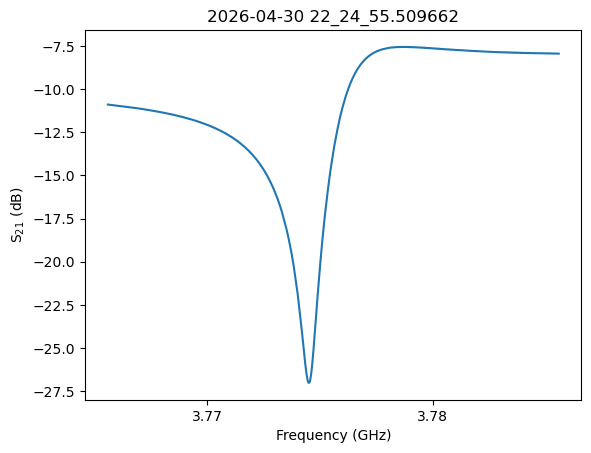

3.9609
20
Started at 2026-04-30 22_25_58.465249


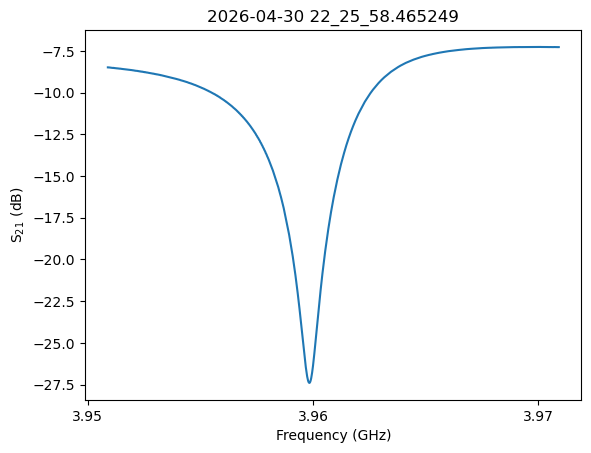

4.2583
20
Started at 2026-04-30 22_27_00.920756


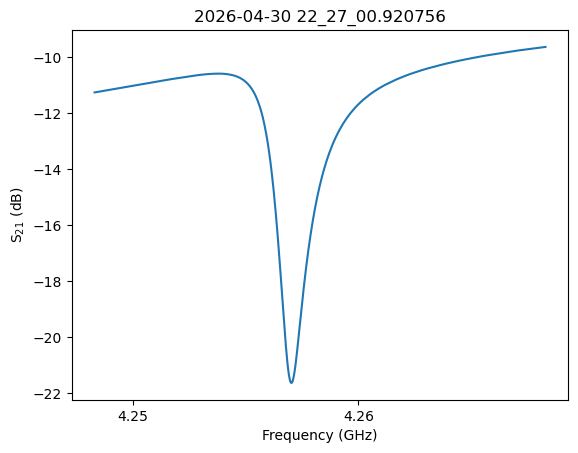

4.4305
20
Started at 2026-04-30 22_28_03.358534


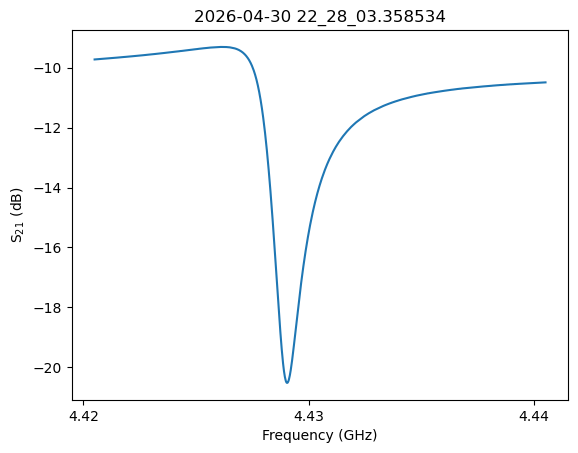

4.625
20
Started at 2026-04-30 22_29_05.804805


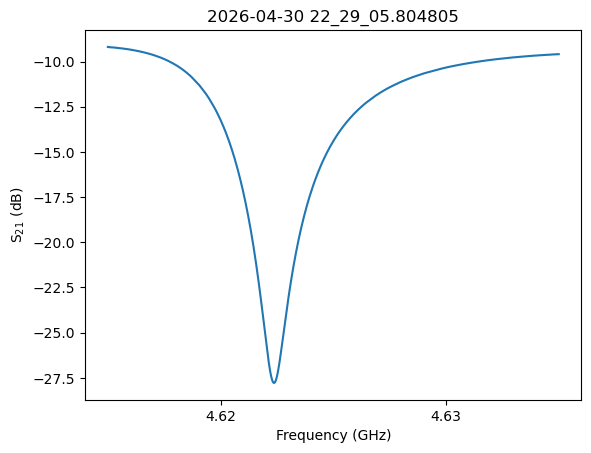

4.8527
20
Started at 2026-04-30 22_30_08.254913


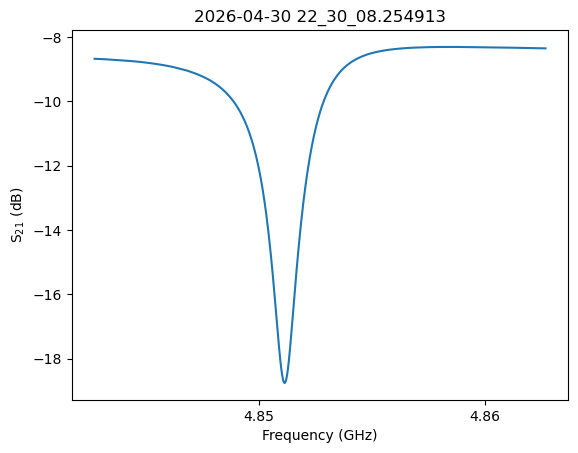

5.163
20
Started at 2026-04-30 22_31_10.683734


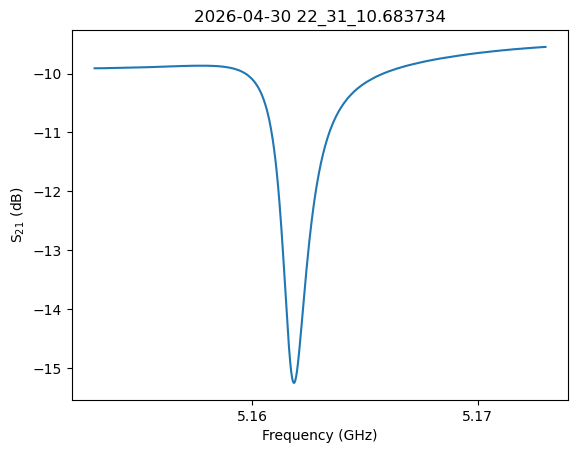

5.404
20
Started at 2026-04-30 22_32_13.126406


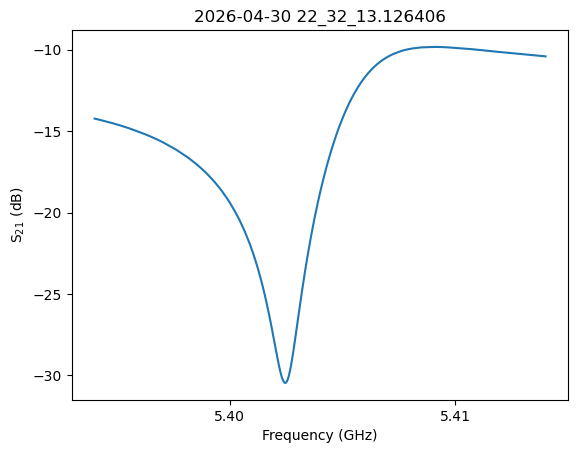

5.5898
20
Started at 2026-04-30 22_33_15.581500


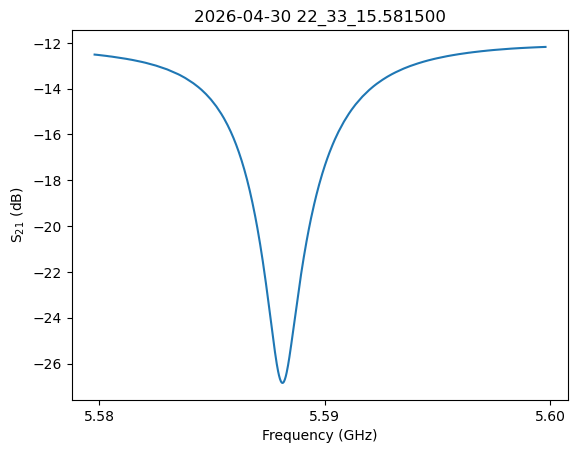

In [16]:
#os.mkdir(path + '\\' + 'trial_res1_04302026')


newpath = path + '\\' + 'trial_res1_04302026'
frequencies = [3.7756, 3.9609, 4.2583, 4.4305, 4.625, 4.8527, 5.163, 5.404, 5.5898]


for freqs in frequencies:

    f, real, imag, times = SingleScan_VNA_realimag(vna_gpib= vna_addr, f = freqs, span = 20, del_time = 60, n_points = 1001, BW = 1E3, power = 0, name = 'test_scan', forplot = True, to_save = True, data_dir = newpath)

In [31]:
df = pd.read_csv(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\trial_res1_04302026\2026-04-30 22_19_42.401199_outarray_test_scan.csv")


freqs = np.array(df.iloc[0, 1:]/1E9)

s_data = np.array(np.sqrt(df.iloc[1, 1:]**2 + df.iloc[2, 1:]**2))

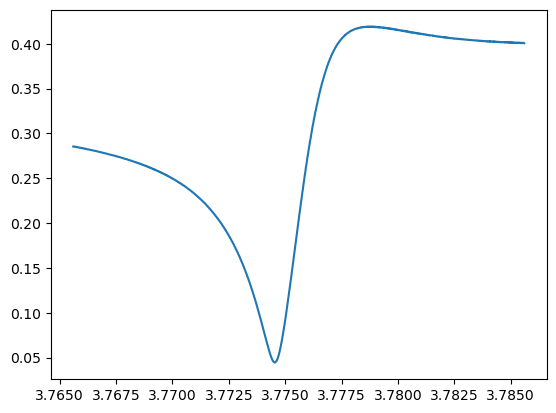

In [32]:
plt.plot(freqs, s_data)

In [33]:
freqs[np.argmin(s_data)]

np.float64(3.77454)

3.7756
20
Started at 2026-04-30 23_48_32.168177


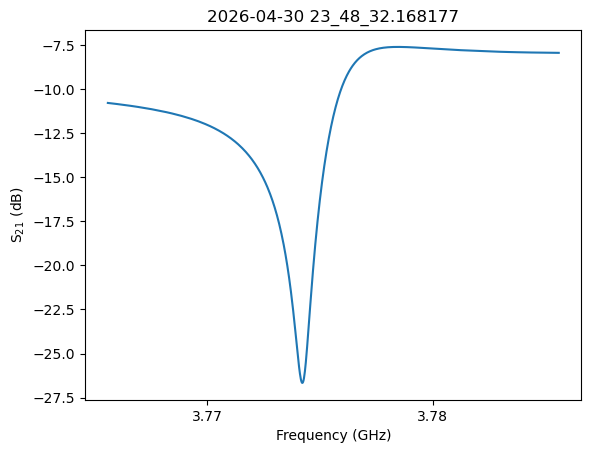

3.77422
3.9609
20
Started at 2026-04-30 23_49_34.650514


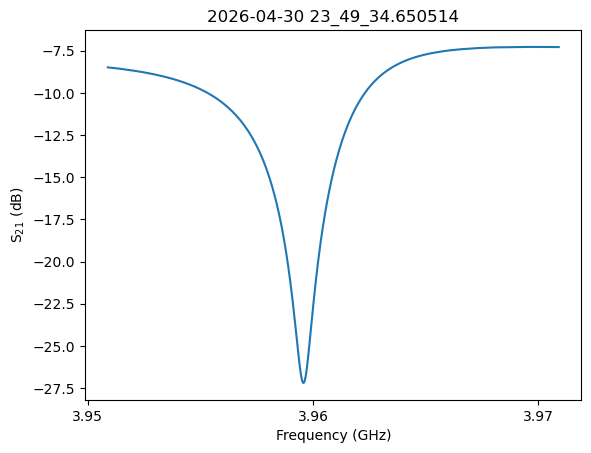

3.95958
4.2583
20
Started at 2026-04-30 23_50_37.584679


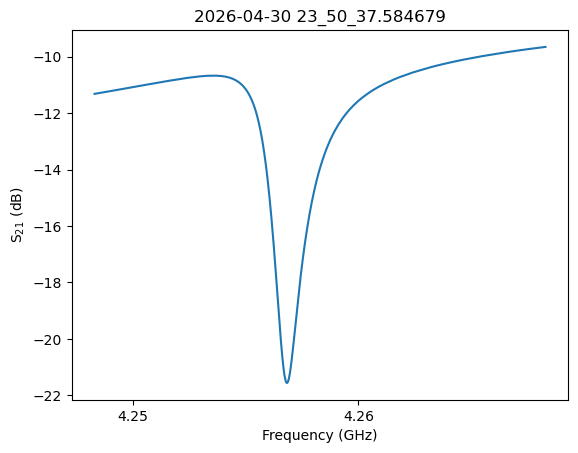

4.25684
4.4305
20
Started at 2026-04-30 23_51_40.020969


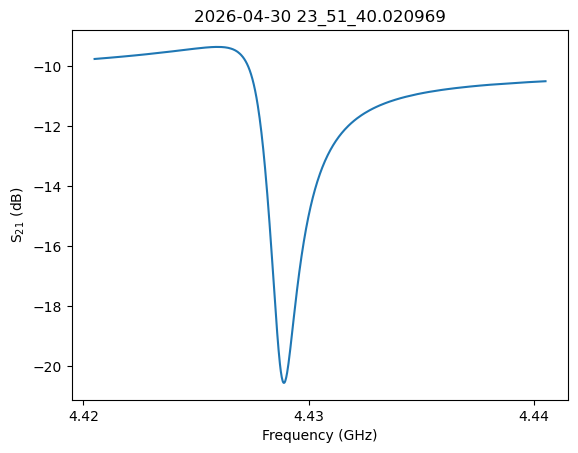

4.4289
4.625
20
Started at 2026-04-30 23_52_42.469987


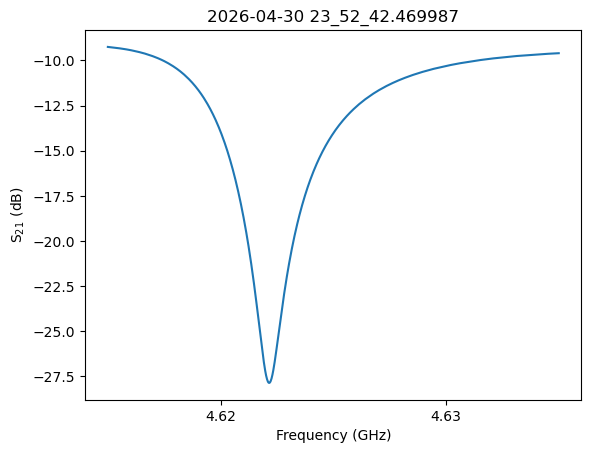

4.62216
4.8527
20
Started at 2026-04-30 23_53_44.930052


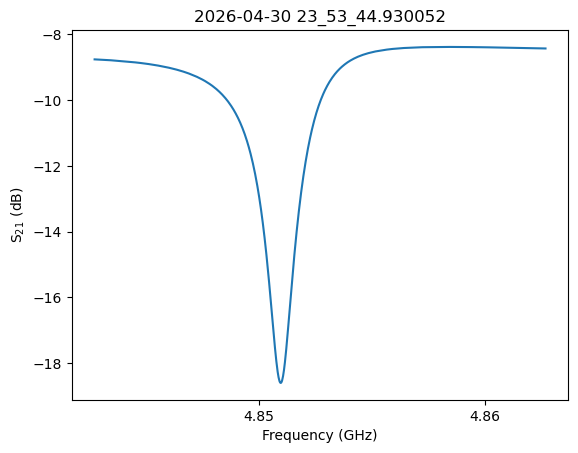

4.85096
5.163
20
Started at 2026-04-30 23_54_47.354579


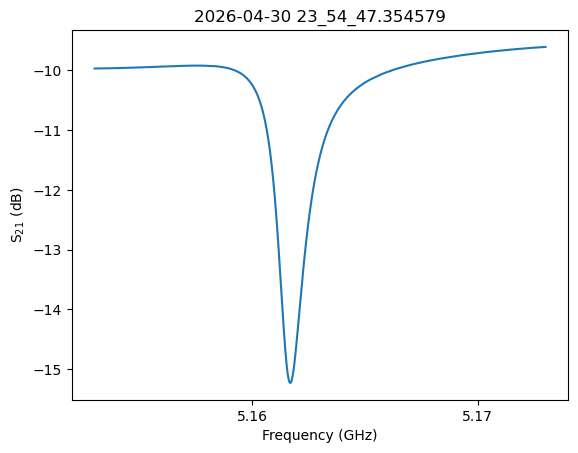

5.16168
5.404
20
Started at 2026-04-30 23_55_49.793070


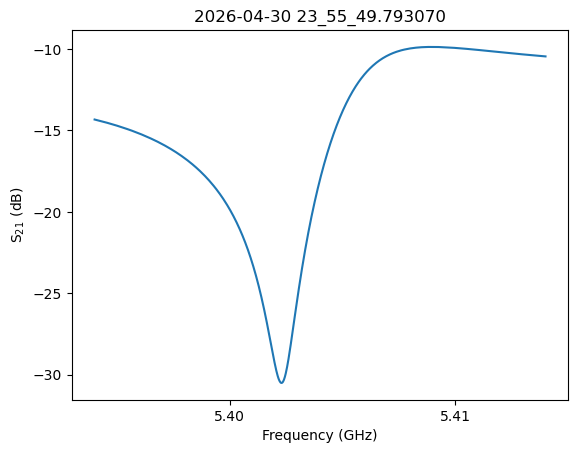

5.40228
5.5898
20
Started at 2026-04-30 23_56_52.225665


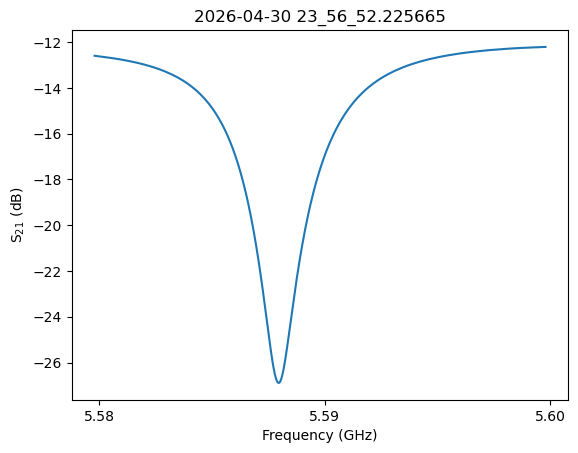

5.58796


In [34]:
os.mkdir(path + '\\' + 'trial_res1neon_04302026')


newpath = path + '\\' + 'trial_res1neon_04302026'
frequencies = [3.7756, 3.9609, 4.2583, 4.4305, 4.625, 4.8527, 5.163, 5.404, 5.5898]


for freqs in frequencies:

    f, real, imag, times = SingleScan_VNA_realimag(vna_gpib= vna_addr, f = freqs, span = 20, del_time = 60, n_points = 1001, BW = 1E3, power = 0, name = 'test_scan', forplot = True, to_save = True, data_dir = newpath)
    s = np.sqrt(real**2 + imag**2)

    print(f[np.argmin(s)])

6
4000
Started at 2026-05-01 14_45_19.738579


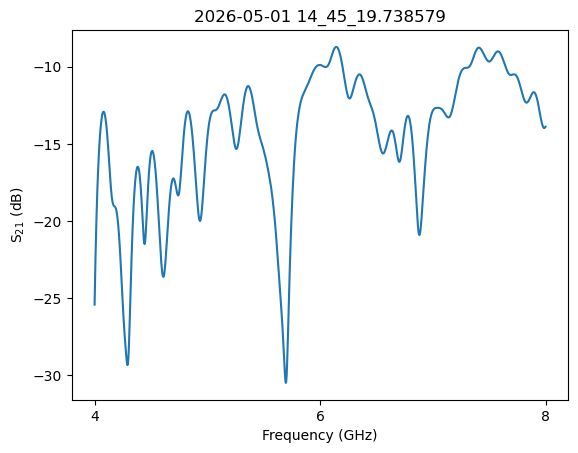

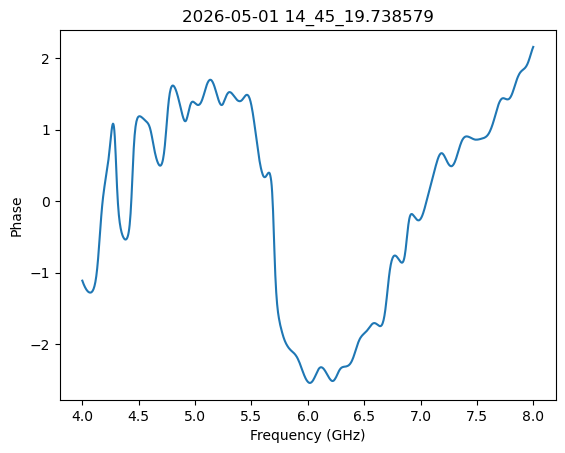

ValueError: too many values to unpack (expected 4, got 5)

In [37]:
#os.mkdir(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\Bruce_pcb")


newpath = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\Bruce_pcb"

f, S, L, times = SingleScan_VNA_phase(vna_addr, f = 6, span = 4000, del_time = 20, n_points = 1001, BW = 1E3, power = 0, name = 'Bruce_data', forplot = True, to_save = True, data_dir = newpath, meas = "S11")

In [39]:
from resonator_tools import circuit


def extract_and_fit(filename, smooth = False):
    data = pd.read_csv(filename)

    f = np.array(data.iloc[0, 1:])

    real = np.array(data.iloc[1, 1:])

    imag = np.array(data.iloc[2, 1:])


    sdata = real + 1j*imag

    port1 = circuit.notch_port()
    
    port1.add_data(f, sdata)


    port1.autofit()

    results = port1.fitresults
    port1.plotall()
    print(results)

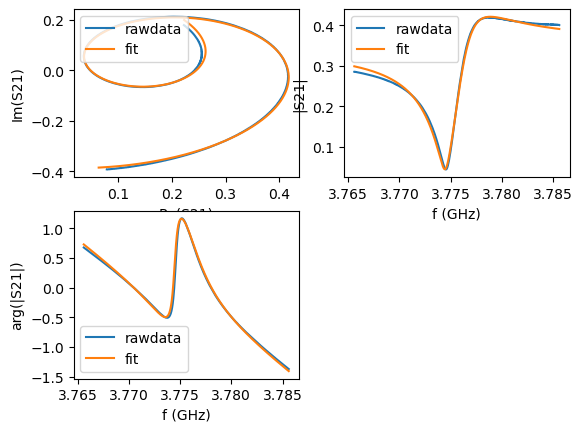

{'Qi_dia_corr': np.float64(5991.721368309884), 'Qi_no_corr': np.float64(-12867.137801430732), 'absQc': np.float64(859.7664593656456), 'Qc_dia_corr': 1088.7408239396436, 'Ql': np.float64(921.3285068439747), 'fr': np.float64(3775806537.3758106), 'theta0': np.float64(2.481097948139834), 'phi0': np.float64(-0.6604947054499594), 'phi0_err': np.float64(0.006457586383521233), 'Ql_err': np.float64(7.007085504240743), 'absQc_err': np.float64(2.352767596008792), 'fr_err': np.float64(13512.727668707837), 'chi_square': np.float64(0.0008583888300330404), 'Qi_no_corr_err': np.float64(1203.3229497397574), 'Qi_dia_corr_err': np.float64(318.6113916753614)}


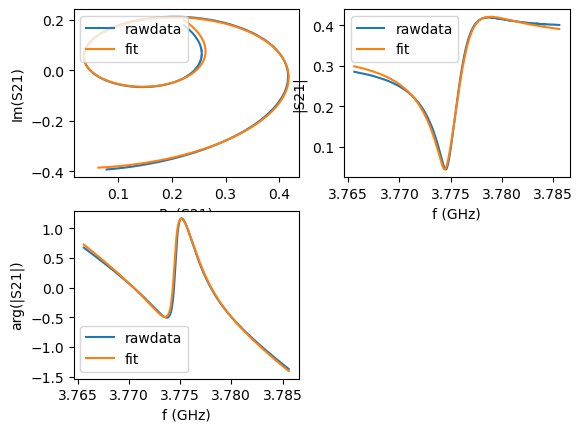

{'Qi_dia_corr': np.float64(5994.274426446386), 'Qi_no_corr': np.float64(-12897.922753970175), 'absQc': np.float64(859.4610491791856), 'Qc_dia_corr': 1087.947341871854, 'Ql': np.float64(920.8204913712236), 'fr': np.float64(3775784645.7422295), 'theta0': np.float64(2.4815793123858914), 'phi0': np.float64(-0.6600133412039019), 'phi0_err': np.float64(0.006441409175697285), 'Ql_err': np.float64(6.983032783663641), 'absQc_err': np.float64(2.368164360636941), 'fr_err': np.float64(13536.240744072098), 'chi_square': np.float64(0.0008703789849638692), 'Qi_no_corr_err': np.float64(1208.9546262383642), 'Qi_dia_corr_err': np.float64(319.47310632235036)}


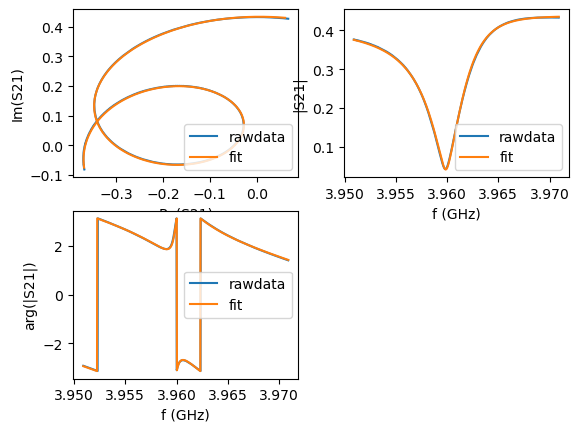

{'Qi_dia_corr': np.float64(6550.107647911532), 'Qi_no_corr': np.float64(9369.150530206483), 'absQc': np.float64(712.3385570585), 'Qc_dia_corr': 736.4362025055945, 'Ql': np.float64(662.0060897533307), 'fr': np.float64(3960579320.9743624), 'theta0': np.float64(2.8850697454253837), 'phi0': np.float64(-0.25652290816440926), 'phi0_err': np.float64(0.0015361422985942735), 'Ql_err': np.float64(1.056259769502203), 'absQc_err': np.float64(0.6163004051626895), 'fr_err': np.float64(4787.416215899479), 'chi_square': np.float64(7.241382034832544e-05), 'Qi_no_corr_err': np.float64(166.1545235712527), 'Qi_dia_corr_err': np.float64(81.89849325873396)}


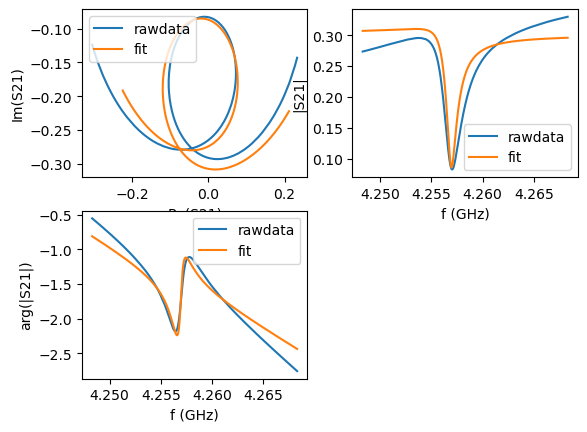

{'Qi_dia_corr': np.float64(8742.328760428014), 'Qi_no_corr': np.float64(9987.393909816463), 'absQc': np.float64(3456.424029163949), 'Qc_dia_corr': 3635.61566981025, 'Ql': np.float64(2567.772671074522), 'fr': np.float64(4256762622.1006002), 'theta0': np.float64(-2.826320934402702), 'phi0': np.float64(0.31527171908720536), 'phi0_err': np.float64(0.07852520136416134), 'Ql_err': np.float64(286.988190808895), 'absQc_err': np.float64(138.69271862899424), 'fr_err': np.float64(71000.8279051448), 'chi_square': np.float64(0.030147643868710525), 'Qi_no_corr_err': np.float64(4708.620453675232), 'Qi_dia_corr_err': np.float64(3876.12219941879)}


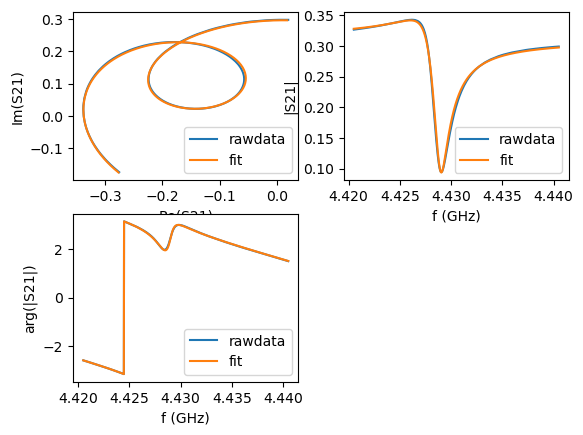

{'Qi_dia_corr': np.float64(5765.201484834757), 'Qi_no_corr': np.float64(9306.483550729685), 'absQc': np.float64(2384.177905637777), 'Qc_dia_corr': 2829.4203373518053, 'Ql': np.float64(1897.9518433275634), 'fr': np.float64(4428487771.047891), 'theta0': np.float64(-2.572960436144049), 'phi0': np.float64(0.568632217317456), 'phi0_err': np.float64(0.005865834852327719), 'Ql_err': np.float64(18.23967370571564), 'absQc_err': np.float64(5.463728546739813), 'fr_err': np.float64(7495.330787366149), 'chi_square': np.float64(0.00014954173288770717), 'Qi_no_corr_err': np.float64(435.25172240830904), 'Qi_dia_corr_err': np.float64(179.1039408670485)}


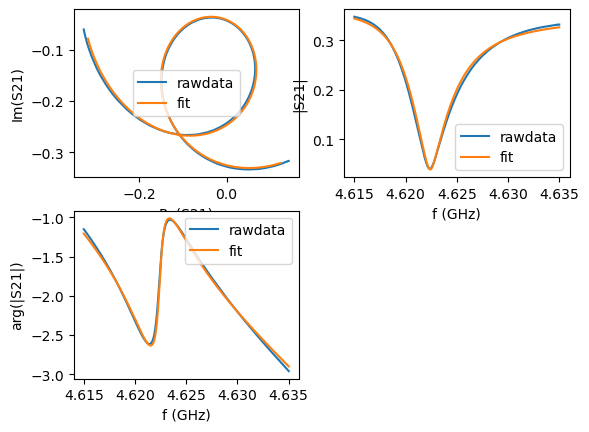

{'Qi_dia_corr': np.float64(6096.806031396798), 'Qi_no_corr': np.float64(7188.7113362592045), 'absQc': np.float64(771.3115654774008), 'Qc_dia_corr': 786.4234225093552, 'Ql': np.float64(696.5728946992793), 'fr': np.float64(4621819094.58112), 'theta0': np.float64(-2.9452369111568353), 'phi0': np.float64(0.19635574243295778), 'phi0_err': np.float64(0.008772426535111065), 'Ql_err': np.float64(4.84720863133838), 'absQc_err': np.float64(2.0886711273743463), 'fr_err': np.float64(29721.839812056205), 'chi_square': np.float64(0.0008170148533788988), 'Qi_no_corr_err': np.float64(470.8983420707067), 'Qi_dia_corr_err': np.float64(341.10819707947593)}


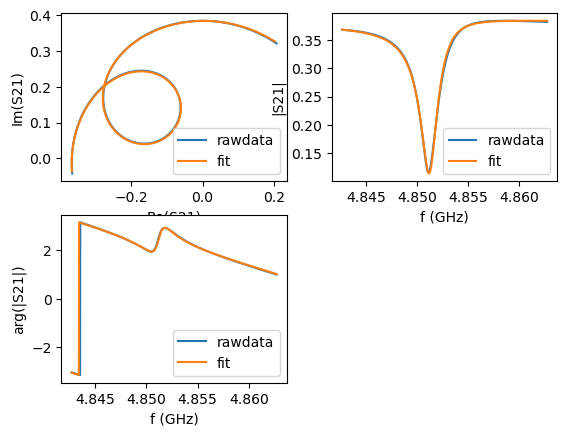

{'Qi_dia_corr': np.float64(5807.525251458503), 'Qi_no_corr': np.float64(6049.305815429432), 'absQc': np.float64(2460.7093915844216), 'Qc_dia_corr': 2503.099366170551, 'Ql': np.float64(1749.1841401558179), 'fr': np.float64(4851372665.21672), 'theta0': np.float64(2.957293924388319), 'phi0': np.float64(-0.1842987291584044), 'phi0_err': np.float64(0.004085720585123927), 'Ql_err': np.float64(8.27310736707714), 'absQc_err': np.float64(5.5581619477166635), 'fr_err': np.float64(6254.251858996699), 'chi_square': np.float64(0.00015320599291402523), 'Qi_no_corr_err': np.float64(88.0871794374314), 'Qi_dia_corr_err': np.float64(77.58966574389642)}


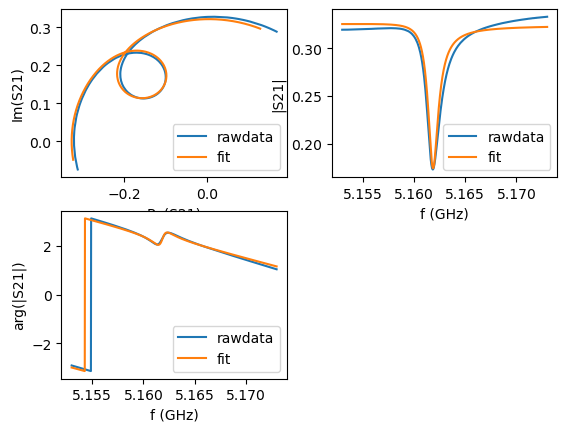

{'Qi_dia_corr': np.float64(6799.548482435842), 'Qi_no_corr': np.float64(6869.227034582342), 'absQc': np.float64(7844.758416007774), 'Qc_dia_corr': 7937.651368506827, 'Ql': np.float64(3662.32702702902), 'fr': np.float64(5161797043.654178), 'theta0': np.float64(-2.9884540006900635), 'phi0': np.float64(0.15313865277146546), 'phi0_err': np.float64(0.04948152295270017), 'Ql_err': np.float64(231.29394029416764), 'absQc_err': np.float64(157.9360828667221), 'fr_err': np.float64(38529.51727917493), 'chi_square': np.float64(0.003518446693581784), 'Qi_no_corr_err': np.float64(817.350840686058), 'Qi_dia_corr_err': np.float64(813.4330912313375)}


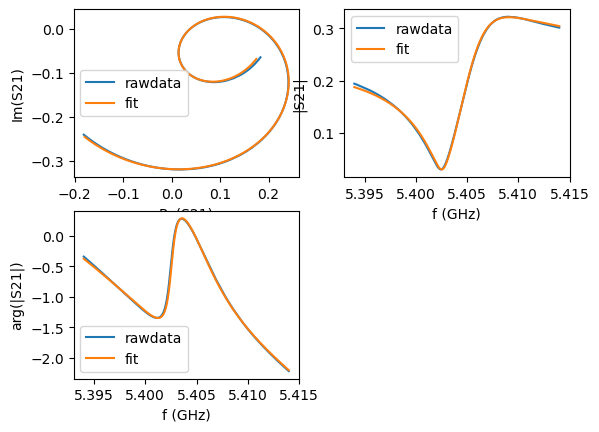

{'Qi_dia_corr': np.float64(5584.167353631921), 'Qi_no_corr': np.float64(-5411.854858782175), 'absQc': np.float64(730.7629327406432), 'Qc_dia_corr': 995.4452524481786, 'Ql': np.float64(844.8419707738236), 'fr': np.float64(5405071703.531748), 'theta0': np.float64(2.395146382633958), 'phi0': np.float64(-0.7464462709558353), 'phi0_err': np.float64(0.002545688695147825), 'Ql_err': np.float64(1.801190552446171), 'absQc_err': np.float64(0.814317481610048), 'fr_err': np.float64(8371.938596401353), 'chi_square': np.float64(0.00021289411824196685), 'Qi_no_corr_err': np.float64(59.8417932315568), 'Qi_dia_corr_err': np.float64(92.17201988227501)}


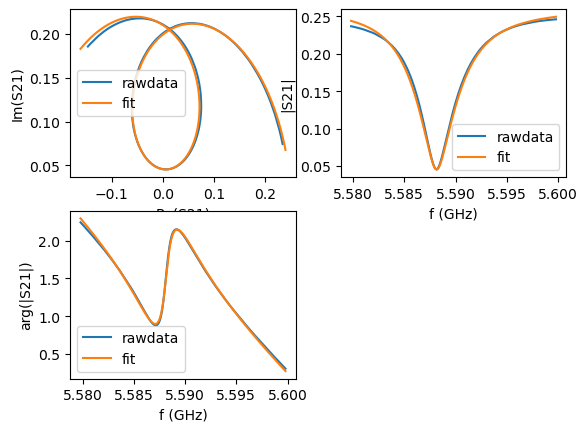

{'Qi_dia_corr': np.float64(4736.781970036475), 'Qi_no_corr': np.float64(4743.218775372754), 'absQc': np.float64(995.4022393661693), 'Qc_dia_corr': 995.6861848192796, 'Ql': np.float64(822.7430559856369), 'fr': np.float64(5588084041.720904), 'theta0': np.float64(-3.117710057178074), 'phi0': np.float64(0.023882596315016203), 'phi0_err': np.float64(0.01000195542491887), 'Ql_err': np.float64(12.163588627189974), 'absQc_err': np.float64(2.2869221106562847), 'fr_err': np.float64(35923.41197475266), 'chi_square': np.float64(0.00047590670204768464), 'Qi_no_corr_err': np.float64(400.6874595538182), 'Qi_dia_corr_err': np.float64(398.50239083518034)}


In [40]:
for file in os.listdir(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\trial_res1_04302026"):

    path = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\trial_res1_04302026" + '\\' + file

    extract_and_fit(path)

3.7756
80
Started at 2026-05-06 12_37_45.320962
3.7656
20
Started at 2026-05-06 12_38_17.440661


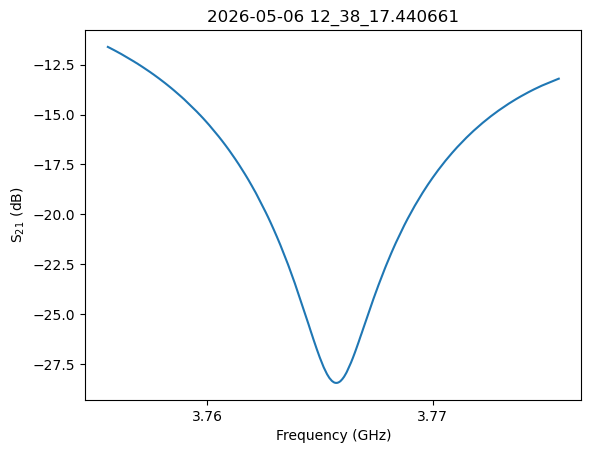

OSError: Cannot save file into a non-existent directory: 'C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\afteranneal_05062025'

In [7]:
#os.mkdir(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\mfcquenchdep_05042026")

#path = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\mfcquenchdep_05042026"


f_search = [3.7756, 3.9609, 4.2583, 4.4305, 4.625, 4.8527, 5.163, 5.404, 5.5898]


for f in f_search:

    f_initial, real, imag, time = SingleScan_VNA_realimag(vna_addr, f = f, span = 80, del_time = 30, n_points = 201, BW = 1E3, power = 0, name = 'init_charac', forplot= False, to_save = False, data_dir = '')

    f_new = f_initial[np.argmin(np.sqrt(real**2 + imag**2))]

    f_final, real, imag, time = SingleScan_VNA_realimag(vna_addr, f = f_new, span = 20, del_time = 30, n_points = 1501, BW = 1E3, power = 0, name = 'basetemp', forplot = True, to_save = True, data_dir = path)


    print(f_final[np.argmin(np.sqrt(real**2 + imag**2))])

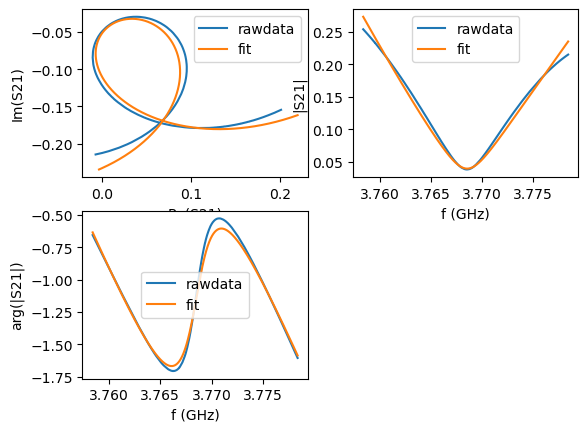

{'Qi_dia_corr': np.float64(1157.30638746049), 'Qi_no_corr': np.float64(-55.19929636954306), 'absQc': np.float64(16.253677774085318), 'Qc_dia_corr': 23.50491762043384, 'Ql': np.float64(23.03703494522053), 'fr': np.float64(3686606083.53709), 'theta0': np.float64(-2.334361405280923), 'phi0': np.float64(0.8072312483088699), 'phi0_err': np.float64(0.00193293451744161), 'Ql_err': np.float64(0.09070380227185616), 'absQc_err': np.float64(0.0304896718920778), 'fr_err': np.float64(3.1614735235707035e-08), 'chi_square': np.float64(8.101139762167569e-06), 'Qi_no_corr_err': np.float64(0.1757507491420226), 'Qi_dia_corr_err': np.float64(21.4792689447276)}


c:\Users\crow104\.conda\envs\spa_ne\Lib\site-packages\resonator_tools\circlefit.py:379: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  x0 = spopt.fsolve(func, 0.0, fprime=d_func)


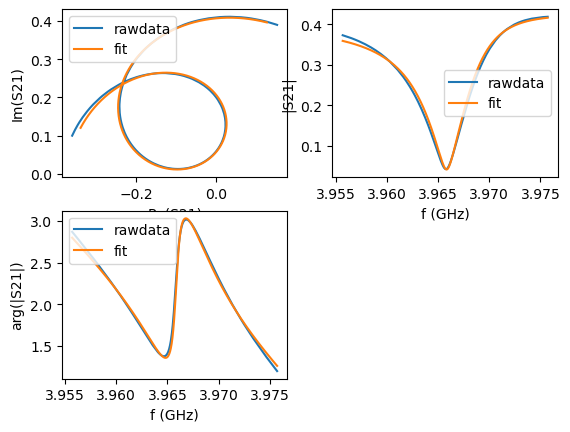

{'Qi_dia_corr': np.float64(5013.5564906412865), 'Qi_no_corr': np.float64(6905.573399192894), 'absQc': np.float64(576.1373666358461), 'Qc_dia_corr': 594.8668218537025, 'Ql': np.float64(531.7712750261393), 'fr': np.float64(3966702885.3887615), 'theta0': np.float64(2.8899908114425013), 'phi0': np.float64(-0.25160184214729203), 'phi0_err': np.float64(0.010180987731235588), 'Ql_err': np.float64(3.7361374366296904), 'absQc_err': np.float64(1.3152351909692146), 'fr_err': np.float64(38494.8495865764), 'chi_square': np.float64(0.0010424359288340628), 'Qi_no_corr_err': np.float64(595.2183278788543), 'Qi_dia_corr_err': np.float64(326.6426650119752)}


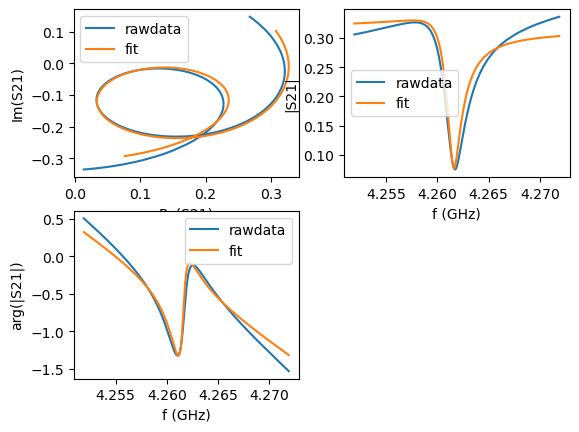

{'Qi_dia_corr': np.float64(7138.848544095467), 'Qi_no_corr': np.float64(9247.310728096025), 'absQc': np.float64(2268.719604690188), 'Qc_dia_corr': 2445.9554511592632, 'Ql': np.float64(1821.76970129754), 'fr': np.float64(4261256730.6419272), 'theta0': np.float64(-2.7585699636941845), 'phi0': np.float64(0.38302268989560867), 'phi0_err': np.float64(0.04698626480273781), 'Ql_err': np.float64(99.82018766941853), 'absQc_err': np.float64(33.168022683321865), 'fr_err': np.float64(60033.9027162067), 'chi_square': np.float64(0.013449624714738588), 'Qi_no_corr_err': np.float64(2654.328507057402), 'Qi_dia_corr_err': np.float64(1656.677421692528)}


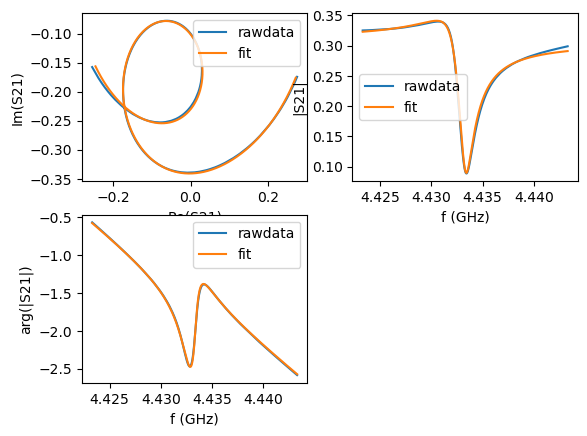

{'Qi_dia_corr': np.float64(5951.217169304638), 'Qi_no_corr': np.float64(10450.734992107351), 'absQc': np.float64(2342.16382533145), 'Qc_dia_corr': 2820.0009206901104, 'Ql': np.float64(1913.353165372715), 'fr': np.float64(4432841877.606811), 'theta0': np.float64(-2.550898496110222), 'phi0': np.float64(0.5906941573787349), 'phi0_err': np.float64(0.003139547083335794), 'Ql_err': np.float64(9.559950936797145), 'absQc_err': np.float64(4.281074643695449), 'fr_err': np.float64(3915.8298124020494), 'chi_square': np.float64(0.00017952453493579973), 'Qi_no_corr_err': np.float64(259.49054376191634), 'Qi_dia_corr_err': np.float64(90.14496825696006)}


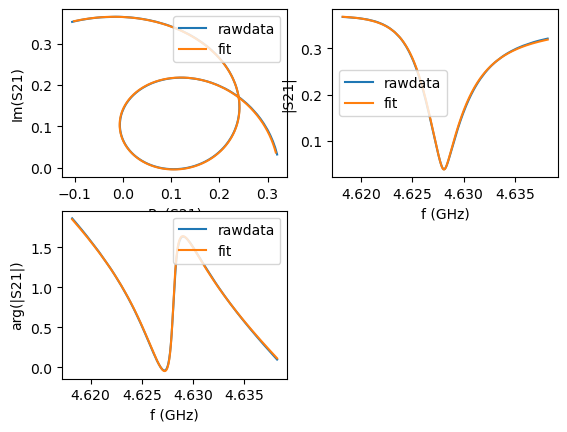

{'Qi_dia_corr': np.float64(6581.633415308315), 'Qi_no_corr': np.float64(9605.145072355841), 'absQc': np.float64(761.5576826569481), 'Qc_dia_corr': 790.3444736110108, 'Ql': np.float64(705.6122082163524), 'fr': np.float64(4627257328.799804), 'theta0': np.float64(-2.870866319815764), 'phi0': np.float64(0.2707263337017608), 'phi0_err': np.float64(0.001318479206579339), 'Ql_err': np.float64(0.8309174069096484), 'absQc_err': np.float64(0.39997334204017504), 'fr_err': np.float64(4372.91275830294), 'chi_square': np.float64(4.7277145135231796e-05), 'Qi_no_corr_err': np.float64(131.06731050113143), 'Qi_dia_corr_err': np.float64(66.52287846320435)}


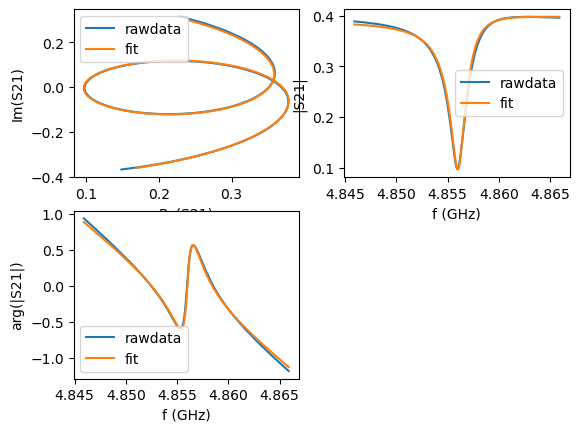

{'Qi_dia_corr': np.float64(7297.3624776123825), 'Qi_no_corr': np.float64(7746.4312609300205), 'absQc': np.float64(2367.2460715641214), 'Qc_dia_corr': 2412.6169358508123, 'Ql': np.float64(1813.159384881801), 'fr': np.float64(4856214816.300063), 'theta0': np.float64(2.9473510313906726), 'phi0': np.float64(-0.1942416221991205), 'phi0_err': np.float64(0.024535165778346166), 'Ql_err': np.float64(22.052225525678033), 'absQc_err': np.float64(8.077587232580624), 'fr_err': np.float64(33216.89974030706), 'chi_square': np.float64(0.0008571389226612422), 'Qi_no_corr_err': np.float64(384.20588728630315), 'Qi_dia_corr_err': np.float64(379.26626942013746)}


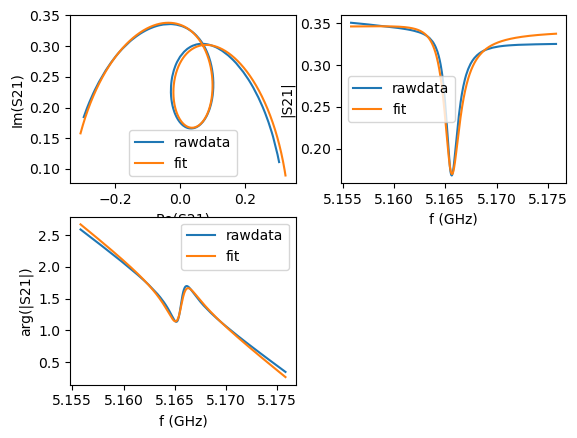

{'Qi_dia_corr': np.float64(4681.328927597346), 'Qi_no_corr': np.float64(4812.624197693542), 'absQc': np.float64(4554.250459101795), 'Qc_dia_corr': 4678.419711048402, 'Ql': np.float64(2339.9369335992515), 'fr': np.float64(5165480093.52306), 'theta0': np.float64(-2.9106853373234864), 'phi0': np.float64(0.2309073162663068), 'phi0_err': np.float64(0.024908419401282723), 'Ql_err': np.float64(114.49199562080582), 'absQc_err': np.float64(47.477162150021194), 'fr_err': np.float64(28900.977534608897), 'chi_square': np.float64(0.002260605640321668), 'Qi_no_corr_err': np.float64(458.3442855969739), 'Qi_dia_corr_err': np.float64(437.43770388095913)}


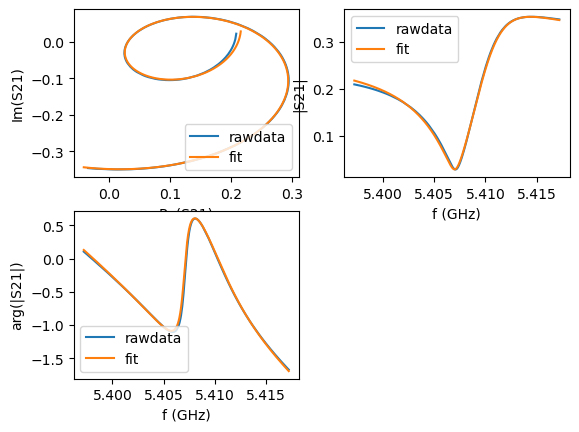

{'Qi_dia_corr': np.float64(6014.074161196226), 'Qi_no_corr': np.float64(-5677.518628980171), 'absQc': np.float64(674.4149259758462), 'Qc_dia_corr': 876.9185284041556, 'Ql': np.float64(765.3255925098781), 'fr': np.float64(5409578086.01234), 'theta0': np.float64(2.448186875038319), 'phi0': np.float64(-0.6934057785514744), 'phi0_err': np.float64(0.005588241363188217), 'Ql_err': np.float64(5.212821317861845), 'absQc_err': np.float64(0.6050905182272783), 'fr_err': np.float64(19954.67915009177), 'chi_square': np.float64(0.00023822504719083753), 'Qi_no_corr_err': np.float64(285.2324240003825), 'Qi_dia_corr_err': np.float64(373.58560392097974)}


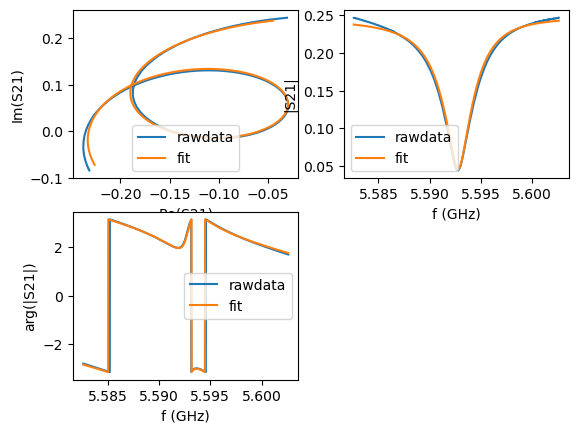

{'Qi_dia_corr': np.float64(6244.013104319802), 'Qi_no_corr': np.float64(6296.252786690036), 'absQc': np.float64(1407.2764704559243), 'Qc_dia_corr': 1409.9129614681194, 'Ql': np.float64(1150.1959819951585), 'fr': np.float64(5592903745.2210865), 'theta0': np.float64(3.0804281164661136), 'phi0': np.float64(-0.06116453712367966), 'phi0_err': np.float64(0.005433413618584586), 'Ql_err': np.float64(6.062431816838768), 'absQc_err': np.float64(3.8800931370223815), 'fr_err': np.float64(14766.510634930675), 'chi_square': np.float64(0.0007570992389151799), 'Qi_no_corr_err': np.float64(163.21596402716594), 'Qi_dia_corr_err': np.float64(160.0536184901719)}


In [64]:
for file in os.listdir(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\basetempsearch_05042026"):

    path = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\basetempsearch_05042026" + '\\' + file

    extract_and_fit(path)

3.7756
80
Started at 2026-05-06 12_39_17.458610
3.7656
20
Started at 2026-05-06 12_39_49.576170


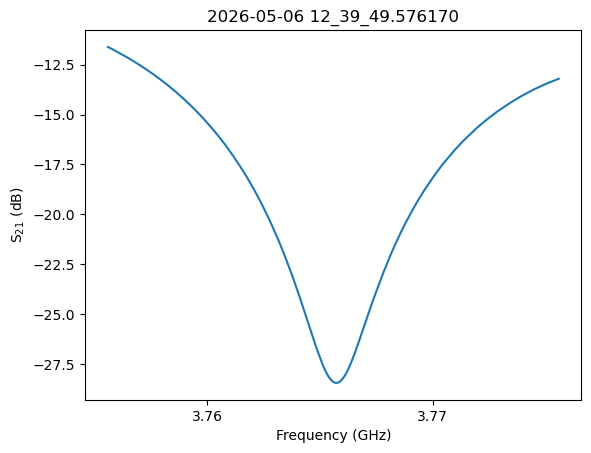

resonant Frequency: 3.76572 GHz
3.9609
80
Started at 2026-05-06 12_40_22.155819
3.9521
20
Started at 2026-05-06 12_40_54.270210


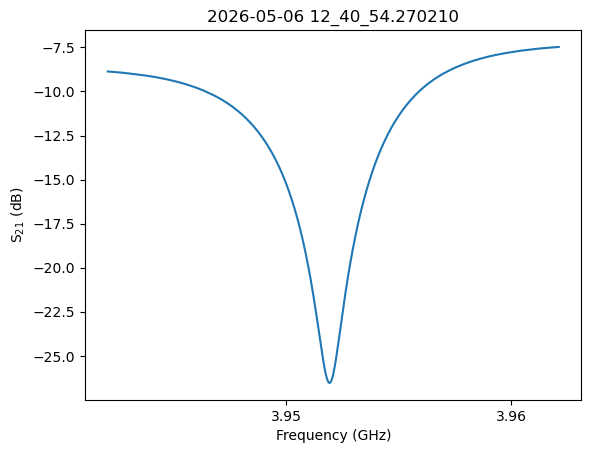

resonant Frequency: 3.9519266666666666 GHz
4.2583
80
Started at 2026-05-06 12_41_26.853229
4.2559
20
Started at 2026-05-06 12_41_58.968273


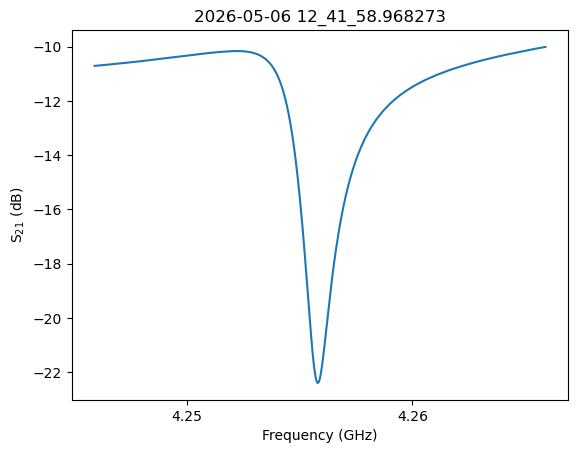

resonant Frequency: 4.2558066666666665 GHz
4.4305
80
Started at 2026-05-06 12_42_31.535788
4.4093
20
Started at 2026-05-06 12_43_03.645008


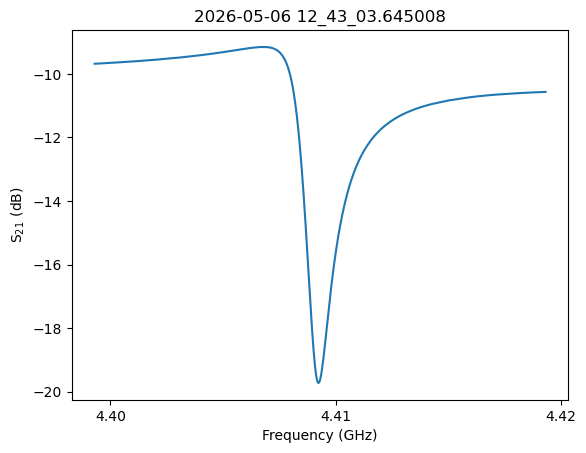

resonant Frequency: 4.409233333333333 GHz
4.625
80
Started at 2026-05-06 12_43_36.218944
4.5966
20
Started at 2026-05-06 12_44_08.333615


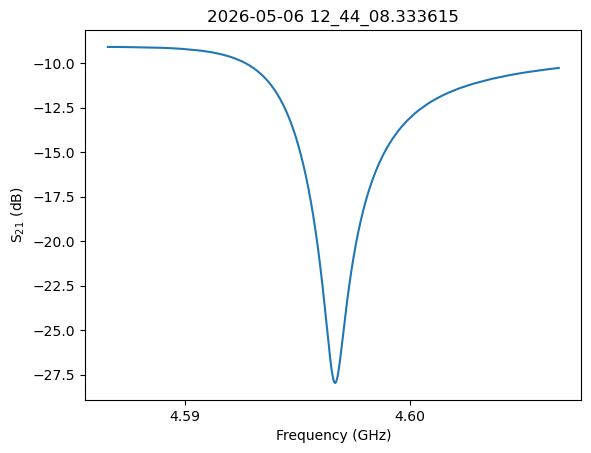

resonant Frequency: 4.59668 GHz
4.8527
80
Started at 2026-05-06 12_44_40.916664
4.8327
20
Started at 2026-05-06 12_45_13.030015


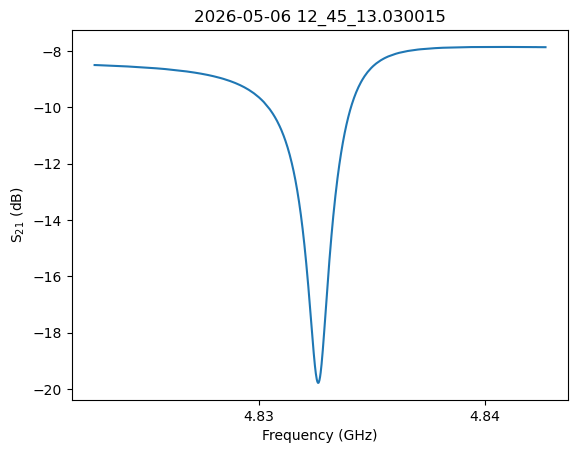

resonant Frequency: 4.83262 GHz
5.163
80
Started at 2026-05-06 12_45_45.605483
5.1626
20
Started at 2026-05-06 12_46_17.718743


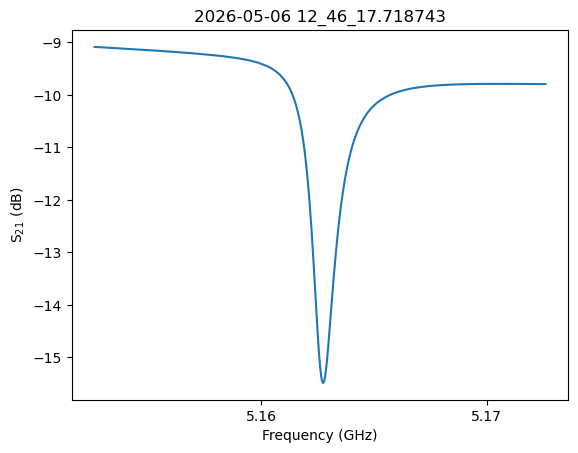

resonant Frequency: 5.162733333333333 GHz
5.404
80
Started at 2026-05-06 12_46_50.293565
5.3948
20
Started at 2026-05-06 12_47_22.392004


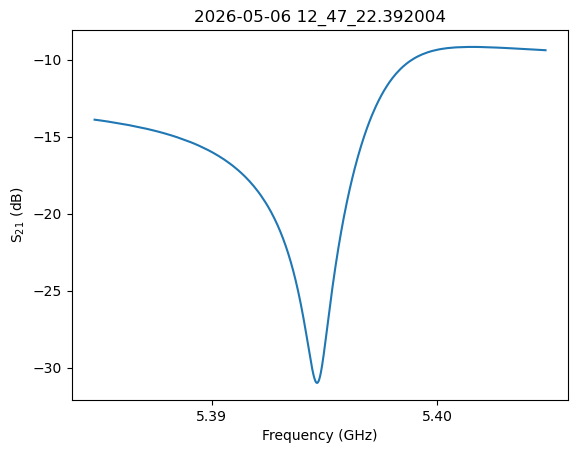

resonant Frequency: 5.394666666666667 GHz
5.5898
80
Started at 2026-05-06 12_47_54.959723
5.5882
20
Started at 2026-05-06 12_48_27.073927


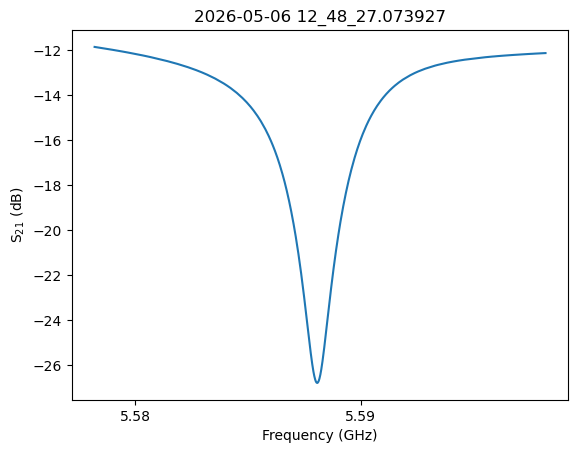

resonant Frequency: 5.58808 GHz


In [8]:
os.makedirs(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\afteranneal_05062026", exist_ok= True)

path = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\afteranneal_05062026"


f_search = [3.7756, 3.9609, 4.2583, 4.4305, 4.625, 4.8527, 5.163, 5.404, 5.5898]

multires_s21_scan(vna_addr, data_dir= path, f_search = f_search, span = 20, name = 'basetemp')

In [21]:
set_current(bkpower_addr, 2, 0.48)

wait_for_stable_resistance()

Channel set to 2

Current set to 0.48
A


c:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Routines\res_to_temp.py:48: RuntimeWarning: divide by zero encountered in log
  log_T = np.log(T)


success!


In [15]:
print(np.linspace(np.sqrt(0.580), np.sqrt(0.450), 51))

[0.76157731 0.75976217 0.75794703 0.7561319  0.75431676 0.75250162
 0.75068648 0.74887134 0.7470562  0.74524107 0.74342593 0.74161079
 0.73979565 0.73798051 0.73616537 0.73435024 0.7325351  0.73071996
 0.72890482 0.72708968 0.72527454 0.72345941 0.72164427 0.71982913
 0.71801399 0.71619885 0.71438371 0.71256858 0.71075344 0.7089383
 0.70712316 0.70530802 0.70349288 0.70167775 0.69986261 0.69804747
 0.69623233 0.69441719 0.69260205 0.69078692 0.68897178 0.68715664
 0.6853415  0.68352636 0.68171122 0.67989608 0.67808095 0.67626581
 0.67445067 0.67263553 0.67082039]


In [20]:
lo_set_frequency("GPIB0::27::INSTR", int(4.56E9))

lo_on_or_off("GPIB0::27::INSTR", 'OFF')

lo_set_power("GPIB0::27::INSTR", 0)

4560000000.000000

0

0.00



In [35]:
arduino = serial.Serial("COM3", 9600, timeout=10)  

arduino.write(b'SYSTem:PRESsure:GETMbar?\n') #Reading pressure
response = arduino.readline().decode('utf-8').strip()


print(response)

arduino.close()

1817


In [32]:
serial.Serial("COM3", 9600, timeout=10).close()

SerialException: could not open port 'COM3': PermissionError(13, 'Access is denied.', None, 5)

In [34]:
rm.list_opened_resources()

rm.close()

In [27]:
set_current(bkpower_addr, 1, 0.45)

Channel set to 1

Current set to 0.45
A


In [31]:
#wait_for_stable_resistance()

print(R2T_900_silent(np.abs(hp34461a_get_ohm_4pt(hp34461a))))

7.504085067169859


In [36]:
voltage_query(bkpower_addr, 1)

'0\n'